# Statistiques des retards et contentieux

Objectif : mesurer les retards et les contentieux de façon fiable, en corrigeant les biais de `notebook_retards.ipynb`.

Choix de méthode :
- **source Koha** (`issues` + `old_issues`) pour les dates : dans `statdb.stat_issues`, `date_due` reste figée à l'émission et n'intègre pas les prolongations (≈ 15 % des prêts, +9 points de taux de retard) ;
- `statdb.stat_issues` sert uniquement au **profil de l'emprunteur au moment du prêt** (catégorie, âge, sexe, fidélité), jointure sur (`itemnumber`, `issuedate`) — l'`issue_id` de statdb n'est pas celui de Koha ;
- retard des prêts non rendus calculé à la **date de fraîcheur des données**, pas à la date du jour ;
- indicateurs **par cohorte d'échéance** : un taux n'est publié que si toute la cohorte a eu le temps d'atteindre le seuil ;
- **plancher / plafond** : le plancher prend les retours Koha tels quels ; le plafond considère comme non récupérés les prêts « rendus » dont l'exemplaire est aujourd'hui en statut perdu / non restitué (retour administratif probable) ;
- les comparaisons se font **au niveau emprunteur** (un usager avec 15 documents ne pèse pas 15 fois), avec intervalles de Wilson à 95 % et tests du χ².

Seuils retenus : contentieux à **42 jours** de retard, puis 90 et 180 jours (seuils de `notebook_retards.ipynb`).

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("darkgrid")

from scipy import stats

from kiblib.utils.db import DbConn

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

In [2]:
db_conn = DbConn().create_engine()

# paramètres
CATEGORIES = ['BIBL', 'MEDA', 'MEDB', 'MEDC', 'CSVT']   # mêmes catégories que notebook_retards
DEBUT_ECHEANCES = '2023-01-01'
SEUILS = [7, 14, 28, 42, 90, 180]
SEUIL_CTX = 42

# Préparation des données

## Date de fraîcheur
La base n'est pas alimentée en continu : on prend le dernier mouvement connu dans Koha (prêt ou retour).

In [3]:
fraicheur = pd.read_sql("""
    SELECT GREATEST(
        (SELECT MAX(issuedate) FROM koha_prod.issues),
        (SELECT MAX(returndate) FROM koha_prod.old_issues)
    ) AS fraicheur""", db_conn).iloc[0, 0]
fraicheur = pd.Timestamp(fraicheur).normalize()
fraicheur

Timestamp('2026-10-14 00:00:00')

## Prêts Koha
Tous les prêts dont l'échéance réelle (prolongations comprises) est postérieure au 1er janvier 2023, avec le statut actuel de l'exemplaire.

In [4]:
query = f"""
SELECT 'en cours' AS source, o.borrowernumber AS borrowernumber_koha, o.itemnumber, o.issuedate, o.date_due,
       o.returndate, o.renewals_count, o.branchcode AS site_pret, i.itemlost, i.itemlost_on
FROM koha_prod.issues o
LEFT JOIN koha_prod.items i ON i.itemnumber = o.itemnumber
WHERE o.date_due >= '{DEBUT_ECHEANCES}'
UNION ALL
SELECT 'rendu', o.borrowernumber, o.itemnumber, o.issuedate, o.date_due,
       o.returndate, o.renewals_count, o.branchcode, i.itemlost, i.itemlost_on
FROM koha_prod.old_issues o
LEFT JOIN koha_prod.items i ON i.itemnumber = o.itemnumber
WHERE o.date_due >= '{DEBUT_ECHEANCES}' AND o.returndate IS NOT NULL
"""
prets = pd.read_sql(query, db_conn)
prets.groupby('source').size()

source
en cours      36723
rendu       1382426
dtype: int64

## Profil des emprunteurs (statdb)
Profil enregistré au moment du prêt. On ne garde que les colonnes utiles et une ligne par (`itemnumber`, `issuedate`).

In [5]:
query = f"""
SELECT itemnumber, issuedate, borrowernumber, categorycode, age, sexe, fidelite, branchcode AS site_inscription
FROM statdb.stat_issues
WHERE issuedate >= DATE_SUB('{DEBUT_ECHEANCES}', INTERVAL 1 YEAR)
"""
profils = pd.read_sql(query, db_conn)
print(len(profils), "lignes ;", profils.duplicated(['itemnumber', 'issuedate']).sum(), "doublons de clé")
profils = profils.drop_duplicates(['itemnumber', 'issuedate'])

1704226 lignes ; 1020 doublons de clé


In [6]:
# dernier prêt connu de chaque exemplaire (calculé avant tout filtre : un prêt ultérieur, même hors périmètre, prouve le retour)
prets['dernier_pret'] = prets['issuedate'] == prets.groupby('itemnumber')['issuedate'].transform('max')

prets = prets.merge(profils, on=['itemnumber', 'issuedate'], how='left', indicator=True)
print(prets['_merge'].value_counts())
print("taux de prêts sans profil statdb :", round(100 * (prets['_merge'] == 'left_only').mean(), 2), "%")

both          1215063
left_only      204086
right_only          0
Name: _merge, dtype: int64
taux de prêts sans profil statdb : 14.38 %


Les prêts sans profil statdb ne peuvent pas être filtrés sur la catégorie : on les écarte. Vérification faite le 15/10/2026 : 99,7 % d'entre eux sont rattachés dans Koha à la catégorie `CGEN` (compte générique), hors périmètre ; les écarter ne biaise donc pas l'étude. Pour l'emprunteur, on prend le `borrowernumber` de statdb (non anonymisé), à défaut celui de Koha.

In [7]:
prets = prets[prets['_merge'] == 'both'].drop(columns='_merge')
prets['borrowernumber'] = prets['borrowernumber'].fillna(prets['borrowernumber_koha'])
prets = prets[prets['categorycode'].isin(CATEGORIES)].copy()

prets['echeance'] = pd.to_datetime(prets['date_due']).dt.normalize()
prets['retour'] = pd.to_datetime(prets['returndate']).dt.normalize()
# on ignore les retours postérieurs à la date de fraîcheur (incohérence éventuelle)
prets.loc[prets['retour'] > fraicheur, 'retour'] = pd.NaT
prets = prets[prets['echeance'] <= fraicheur]

# retard en jours : au retour, ou à la date de fraîcheur si non rendu
prets['retard'] = ((prets['retour'].fillna(fraicheur) - prets['echeance']) / np.timedelta64(1, 'D')).astype(int)
prets['non_rendu'] = prets['retour'].isna()
# plafond : retour possiblement administratif = prêt "rendu" en retard, dernier prêt de l'exemplaire,
# et exemplaire aujourd'hui perdu / non restitué. Si l'exemplaire a été reprêté ensuite, le retour était réel.
prets['retour_douteux'] = ((~prets['non_rendu']) & prets['dernier_pret']
                           & prets['itemlost'].isin([1, 2]) & (prets['retard'] > 0))
prets['mois_echeance'] = prets['echeance'].dt.to_period('M')

print(len(prets), "prêts retenus,", prets['borrowernumber'].nunique(), "emprunteurs")
prets.groupby('non_rendu').size()

1010282 prêts retenus, 21383 emprunteurs


non_rendu
False    1004497
True        5785
dtype: int64

### Contrôle : les retours douteux
Prêts rendus en retard, qui sont le dernier prêt de l'exemplaire, et dont l'exemplaire est aujourd'hui en statut 1 (non restitué) ou 2 (perdu) : le « retour » peut correspondre à la mise en perte plutôt qu'à un retour physique. Ils ne servent qu'au calcul du plafond.

Un exemplaire perdu lors d'un prêt *ultérieur* ne rend pas douteux les retours précédents (il a forcément été rendu pour être reprêté) : ces cas sont exclus.

In [8]:
prets[prets['retour_douteux']].groupby('itemlost').agg(n=('itemnumber', 'size'), retard_median=('retard', 'median'))

,n,retard_median
itemlost,,
1.0,64,52.0
2.0,68,18.0


# 1. Taux de retard par cohorte d'échéance (niveau prêt)

Pour chaque mois d'échéance, part des prêts **toujours pas rendus J jours après l'échéance**. Une valeur n'est affichée que si le dernier jour du mois + J est antérieur à la date de fraîcheur (cohorte complète).
- plancher : retours Koha tels quels ;
- plafond : retours douteux comptés comme non rendus.

In [9]:
def taux_cohortes(df, seuils, douteux_non_rendu=False):
    res = {}
    fin_mois = df['mois_echeance'].dt.to_timestamp(how='end').dt.normalize()
    for s in seuils:
        en_retard = df['retard'] > s
        if douteux_non_rendu:
            en_retard = en_retard | (df['retour_douteux'] & ((fraicheur - df['echeance']).dt.days > s))
        complet = (fin_mois + pd.Timedelta(days=s)) <= fraicheur
        t = en_retard.groupby(df['mois_echeance']).mean()
        t[~complet.groupby(df['mois_echeance']).all()] = np.nan
        res[f'> {s} j'] = t
    out = pd.DataFrame(res)
    out.insert(0, 'prets', df.groupby('mois_echeance').size())
    return out

plancher = taux_cohortes(prets, SEUILS)
plafond = taux_cohortes(prets, SEUILS, douteux_non_rendu=True)
(plancher.drop(columns='prets') * 100).round(2).join(plancher['prets'])

,> 7 j,> 14 j,> 28 j,> 42 j,> 90 j,> 180 j,prets
mois_echeance,,,,,,,
2023-01,13.03,8.14,3.24,1.51,0.57,0.45,18586
2023-02,13.79,8.90,3.62,2.17,0.66,0.50,17890
2023-03,12.86,9.24,4.03,2.27,0.85,0.46,22368
2023-04,15.02,10.12,4.36,2.34,0.72,0.65,17928
2023-05,15.20,10.88,4.89,2.62,0.92,0.65,17946
2023-06,13.98,9.30,3.68,1.62,0.72,0.41,18207
2023-07,12.63,8.30,3.78,1.99,0.48,0.38,17363
2023-08,16.81,11.10,4.67,2.73,0.95,0.64,18509
2023-09,14.41,9.12,3.54,1.46,0.38,0.30,16601


In [10]:
print("écart plafond - plancher, en points (max sur la période) :")
((plafond - plancher).drop(columns='prets') * 100).max().round(3)

écart plafond - plancher, en points (max sur la période) :


> 7 j      0.021
> 14 j     0.030
> 28 j     0.030
> 42 j     0.030
> 90 j     0.040
> 180 j    0.036
dtype: float64

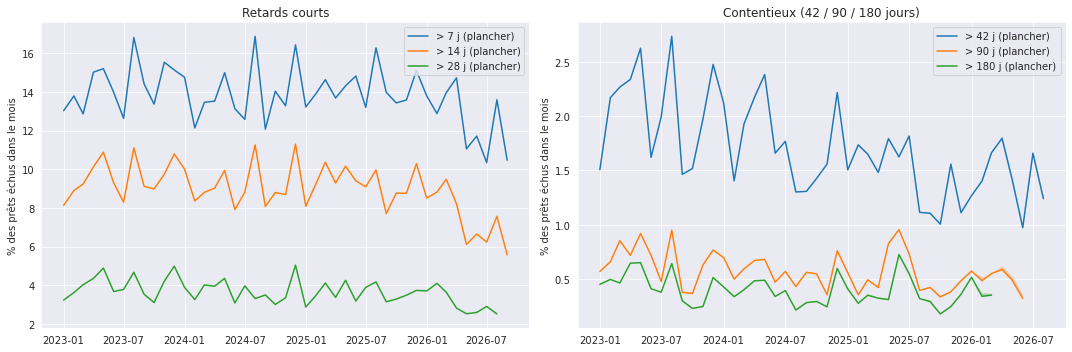

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, cols in zip(axes, [['> 7 j', '> 14 j', '> 28 j'], ['> 42 j', '> 90 j', '> 180 j']]):
    for c in cols:
        x = plancher.index.to_timestamp()
        ax.plot(x, plancher[c] * 100, label=f'{c} (plancher)')
        ax.fill_between(x, plancher[c] * 100, plafond[c] * 100, alpha=0.3)
    ax.set_ylabel('% des prêts échus dans le mois')
    ax.legend()
axes[0].set_title('Retards courts')
axes[1].set_title('Contentieux (42 / 90 / 180 jours)')
plt.tight_layout()
plt.show()

# 2. Stock de contentieux en fin de mois (vue opérationnelle)

À chaque fin de mois D : prêts dont l'échéance + 42 jours est dépassée et qui ne sont pas rendus à D — c'est la liste des personnes à relancer à cette date. On compte les prêts et les emprunteurs distincts.

In [12]:
fins_mois = pd.date_range('2023-03-31', fraicheur, freq='M')
stock = []
for d in fins_mois:
    s = prets[(prets['echeance'] + pd.Timedelta(days=SEUIL_CTX) < d) & ((prets['retour'].isna()) | (prets['retour'] > d))]
    s_plafond = prets[(prets['echeance'] + pd.Timedelta(days=SEUIL_CTX) < d) & ((prets['retour'].isna()) | (prets['retour'] > d) | prets['retour_douteux'])]
    stock.append({'date': d.date(),
                  'prets': len(s), 'emprunteurs': s['borrowernumber'].nunique(),
                  'prets_plafond': len(s_plafond), 'emprunteurs_plafond': s_plafond['borrowernumber'].nunique(),
                  'docs_par_emprunteur': round(len(s) / max(s['borrowernumber'].nunique(), 1), 2)})
stock = pd.DataFrame(stock).set_index('date')
stock

,prets,emprunteurs,prets_plafond,emprunteurs_plafond,docs_par_emprunteur
date,,,,,
2023-03-31,321,126,321,126,2.55
2023-04-30,454,189,454,189,2.40
2023-05-31,548,211,548,211,2.60
2023-06-30,650,254,650,254,2.56
2023-07-31,794,303,795,304,2.62
2023-08-31,864,342,865,343,2.53
2023-09-30,884,330,885,331,2.68
2023-10-31,907,350,909,352,2.59
2023-11-30,964,366,968,370,2.63


Attention : le stock en début de période est sous-estimé, car seuls les prêts échus depuis le 1er janvier 2023 sont chargés (les contentieux plus anciens toujours ouverts n'y figurent pas). Le stock n'est complet qu'en contrôlant ce volume :

In [13]:
anciens = pd.read_sql(f"""
    SELECT COUNT(*) AS prets, COUNT(DISTINCT borrowernumber) AS emprunteurs
    FROM koha_prod.issues WHERE date_due < '{DEBUT_ECHEANCES}'""", db_conn)
print("prêts encore en cours échus avant", DEBUT_ECHEANCES, "(toutes catégories) :")
anciens

prêts encore en cours échus avant 2023-01-01 (toutes catégories) :


,prets,emprunteurs
0,4808,1458


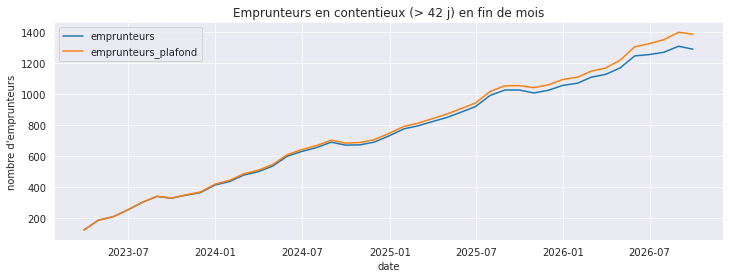

In [14]:
ax = stock[['emprunteurs', 'emprunteurs_plafond']].plot(figsize=(12, 4), title='Emprunteurs en contentieux (> 42 j) en fin de mois')
ax.set_ylabel("nombre d'emprunteurs")
plt.show()

# 3. Taux d'emprunteurs en contentieux (niveau emprunteur)

Unité : le couple (emprunteur, année d'échéance). Un emprunteur est **en contentieux** une année s'il a au moins un prêt échu cette année-là et non rendu à J+42. Le dénominateur est le nombre d'emprunteurs ayant au moins un prêt échu dans l'année.

Seules les années complètes à J+42 sont retenues.

In [15]:
prets['annee_echeance'] = prets['echeance'].dt.year
prets['ctx'] = prets['retard'] > SEUIL_CTX
prets['ctx_plafond'] = prets['ctx'] | (prets['retour_douteux'] & ((fraicheur - prets['echeance']).dt.days > SEUIL_CTX))

annees_completes = [a for a in sorted(prets['annee_echeance'].unique())
                    if pd.Timestamp(f'{a}-12-31') + pd.Timedelta(days=SEUIL_CTX) <= fraicheur]

emp = (prets[prets['annee_echeance'].isin(annees_completes)]
       .sort_values('issuedate')
       .groupby(['annee_echeance', 'borrowernumber'])
       .agg(ctx=('ctx', 'max'), ctx_plafond=('ctx_plafond', 'max'),
            prets=('itemnumber', 'size'), prets_ctx=('ctx', 'sum'),
            categorycode=('categorycode', 'last'), age=('age', 'last'),
            sexe=('sexe', 'last'), fidelite=('fidelite', 'last'),
            site=('site_pret', 'last'))
       .reset_index())
print("années retenues :", annees_completes)

années retenues : [2023, 2024, 2025]


In [16]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    demi = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - demi, centre + demi

def tableau_taux(df, groupe):
    t = df.groupby(groupe).agg(emprunteurs=('ctx', 'size'), ctx=('ctx', 'sum'), ctx_plafond=('ctx_plafond', 'sum'))
    t['taux_plancher_%'] = 100 * t['ctx'] / t['emprunteurs']
    t['taux_plafond_%'] = 100 * t['ctx_plafond'] / t['emprunteurs']
    bas, haut = wilson(t['ctx'], t['emprunteurs'])
    _, haut_plafond = wilson(t['ctx_plafond'], t['emprunteurs'])
    t['IC95_bas_%'] = 100 * bas
    t['IC95_haut_%'] = 100 * haut_plafond
    return t.round(2)

par_annee = tableau_taux(emp, 'annee_echeance')
par_annee

,emprunteurs,ctx,ctx_plafond,taux_plancher_%,taux_plafond_%,IC95_bas_%,IC95_haut_%
annee_echeance,,,,,,,
2023,10689,1509,1514,14.12,14.16,13.47,14.84
2024,11232,1569,1572,13.97,14.00,13.34,14.65
2025,11044,1298,1315,11.75,11.91,11.17,12.52


Comparaison des deux dernières années complètes : test du χ² d'homogénéité. Les deux années partagent une partie des emprunteurs, donc le test est approximatif (échantillons non indépendants) ; on le complète par un test de McNemar sur les emprunteurs présents les deux années.

In [17]:
if len(annees_completes) >= 2:
    a1, a2 = annees_completes[-2], annees_completes[-1]
    for col in ['ctx', 'ctx_plafond']:
        sub = emp[emp['annee_echeance'].isin([a1, a2])]
        ct = pd.crosstab(sub['annee_echeance'], sub[col])
        chi2, p, _, _ = stats.chi2_contingency(ct)
        print(f"{col} : {a1} vs {a2}  χ² = {chi2:.2f}, p = {p:.4f}")

    # McNemar exact sur les emprunteurs présents les deux années
    paire = (emp[emp['annee_echeance'].isin([a1, a2])]
             .pivot(index='borrowernumber', columns='annee_echeance', values='ctx').dropna())
    b = int(((paire[a1] == True) & (paire[a2] == False)).sum())
    c = int(((paire[a1] == False) & (paire[a2] == True)).sum())
    p_mcnemar = stats.binomtest(b, b + c, 0.5).pvalue if hasattr(stats, 'binomtest') else stats.binom_test(b, b + c, 0.5)
    print(f"McNemar ({len(paire)} emprunteurs présents les deux années) : sortis du contentieux = {b}, entrés = {c}, p = {p_mcnemar:.4f}")

ctx : 2024 vs 2025  χ² = 24.19, p = 0.0000
ctx_plafond : 2024 vs 2025  χ² = 21.35, p = 0.0000
McNemar (6834 emprunteurs présents les deux années) : sortis du contentieux = 435, entrés = 485, p = 0.1062


# 4. Profil des emprunteurs en contentieux

Sur la dernière année complète. Pour chaque dimension : taux par groupe (plancher / plafond, IC 95 %) et test du χ² d'indépendance (plancher).

In [18]:
derniere = emp[emp['annee_echeance'] == annees_completes[-1]].copy()

derniere['age_n'] = pd.to_numeric(derniere['age'], errors='coerce')
derniere['tranche_age'] = pd.cut(derniere['age_n'], [-1, 11, 17, 24, 39, 59, 74, 200],
                                 labels=['0-11', '12-17', '18-24', '25-39', '40-59', '60-74', '75+'])
derniere['anciennete'] = pd.cut(pd.to_numeric(derniere['fidelite'], errors='coerce'), [-1, 0, 2, 5, 10, 100],
                                labels=['< 1 an', '1-2 ans', '3-5 ans', '6-10 ans', '> 10 ans'])
derniere['volume_prets'] = pd.cut(derniere['prets'], [0, 2, 5, 10, 25, 10000],
                                  labels=['1-2', '3-5', '6-10', '11-25', '> 25'])

def test_chi2(df, groupe):
    ct = pd.crosstab(df[groupe], df['ctx'])
    ct = ct[ct.sum(axis=1) >= 30]   # groupes trop petits exclus du test
    chi2, p, ddl, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return f"χ² = {chi2:.1f}, ddl = {ddl}, p = {p:.2g}, V de Cramér = {v:.3f}"

for dim in ['categorycode', 'tranche_age', 'sexe', 'anciennete', 'site', 'volume_prets']:
    print(f"\n=== {dim} — {test_chi2(derniere, dim)}")
    display(tableau_taux(derniere, dim))


=== categorycode — χ² = 18.7, ddl = 4, p = 0.00088, V de Cramér = 0.041


,emprunteurs,ctx,ctx_plafond,taux_plancher_%,taux_plafond_%,IC95_bas_%,IC95_haut_%
categorycode,,,,,,,
BIBL,10229,1225,1236,11.98,12.08,11.36,12.73
CSVT,148,18,18,12.16,12.16,7.83,18.41
MEDA,165,6,7,3.64,4.24,1.68,8.50
MEDB,211,12,14,5.69,6.64,3.28,10.83
MEDC,291,37,40,12.71,13.75,9.37,18.18



=== tranche_age — χ² = 133.0, ddl = 6, p = 2.9e-26, V de Cramér = 0.110


,emprunteurs,ctx,ctx_plafond,taux_plancher_%,taux_plafond_%,IC95_bas_%,IC95_haut_%
tranche_age,,,,,,,
0-11,3452,513,516,14.86,14.95,13.71,16.18
12-17,1653,235,238,14.22,14.40,12.62,16.17
18-24,920,103,104,11.20,11.30,9.32,13.51
25-39,1690,202,204,11.95,12.07,10.49,13.71
40-59,2250,212,218,9.42,9.69,8.28,10.98
60-74,816,28,30,3.43,3.68,2.38,5.20
75+,263,5,5,1.90,1.90,0.81,4.37



=== sexe — χ² = 2.1, ddl = 1, p = 0.15, V de Cramér = 0.014


...

,emprunteurs,ctx,ctx_plafond,taux_plancher_%,taux_plafond_%,IC95_bas_%,IC95_haut_%
anciennete,,,,,,,
< 1 an,2766,364,366,13.16,13.23,11.95,14.55
1-2 ans,3292,393,398,11.94,12.09,10.87,13.25
3-5 ans,2042,228,232,11.17,11.36,9.87,12.81
6-10 ans,1671,197,201,11.79,12.03,10.33,13.68
> 10 ans,1269,116,118,9.14,9.30,7.68,11.02



=== site — χ² = 10.5, ddl = 1, p = 0.0012, V de Cramér = 0.031


,emprunteurs,ctx,ctx_plafond,taux_plancher_%,taux_plafond_%,IC95_bas_%,IC95_haut_%
site,,,,,,,
BUS,492,81,81,16.46,16.46,13.45,20.00
MED,10552,1217,1234,11.53,11.69,10.94,12.32



=== volume_prets — χ² = 50.6, ddl = 4, p = 2.7e-10, V de Cramér = 0.068


,emprunteurs,ctx,ctx_plafond,taux_plancher_%,taux_plafond_%,IC95_bas_%,IC95_haut_%
volume_prets,,,,,,,
1-2,1976,245,246,12.40,12.45,11.02,13.98
3-5,1813,221,224,12.19,12.36,10.76,13.95
6-10,1908,276,277,14.47,14.52,12.96,16.17
11-25,2317,301,305,12.99,13.16,11.68,14.60
> 25,3030,255,263,8.42,8.68,7.48,9.74


Note : `volume_prets` est mécaniquement lié au contentieux (plus on emprunte, plus on a d'occasions d'être en retard). On regarde donc aussi le taux **au niveau prêt** par catégorie, pour séparer « exposition » et « comportement ».

In [19]:
pd.DataFrame({
    'prets': prets[prets['annee_echeance'] == annees_completes[-1]].groupby('categorycode').size(),
    'taux_pret_ctx_%': (100 * prets[prets['annee_echeance'] == annees_completes[-1]].groupby('categorycode')['ctx'].mean()).round(2),
})

,prets,taux_pret_ctx_%
categorycode,,
BIBL,215561,1.68
CSVT,7889,0.91
MEDA,17326,0.38
MEDB,16702,0.40
MEDC,20711,1.11


# 5. Récupération des documents en contentieux

Parmi les prêts ayant dépassé 42 jours de retard, part finalement rendue dans les 90, 180 et 365 jours suivant l'échéance. Même règle de cohorte complète que plus haut (calcul par année d'échéance).

In [20]:
ctx = prets[prets['ctx']].copy()
recup = {}
for horizon in [90, 180, 365]:
    rendu = (~ctx['non_rendu']) & (ctx['retard'] <= horizon)
    rendu_plafond = rendu & ~ctx['retour_douteux']   # plafond du contentieux = plancher de la récupération
    complet = pd.to_datetime(ctx['annee_echeance'].astype(str) + '-12-31') + pd.Timedelta(days=horizon) <= fraicheur
    g = ctx.assign(rendu=rendu, rendu_plafond=rendu_plafond)[complet].groupby('annee_echeance')
    recup[f'rendu ≤ {horizon} j (haut)_%'] = 100 * g['rendu'].mean()
    recup[f'rendu ≤ {horizon} j (bas)_%'] = 100 * g['rendu_plafond'].mean()
recup = pd.DataFrame(recup).round(1)
recup.insert(0, 'prets_ctx', ctx.groupby('annee_echeance').size())
recup

,prets_ctx,rendu ≤ 90 j (haut)_%,rendu ≤ 90 j (bas)_%,rendu ≤ 180 j (haut)_%,rendu ≤ 180 j (bas)_%,rendu ≤ 365 j (haut)_%,rendu ≤ 365 j (bas)_%
annee_echeance,,,,,,,
2023,4727,67.4,67.4,78.2,78.1,82.5,82.4
2024,4735,67.9,67.8,78.8,78.6,81.9,81.8
2025,4052,63.5,63.5,75.3,75.2,NaN,NaN


In [21]:
print("Prêts en contentieux toujours non rendus, selon le statut actuel de l'exemplaire :")
ctx[ctx['non_rendu']].groupby(['annee_echeance', 'itemlost']).size().unstack(fill_value=0)

Prêts en contentieux toujours non rendus, selon le statut actuel de l'exemplaire :


itemlost,0.0,1.0,2.0
annee_echeance,,,
2023,15,706,1
2024,10,706,0
2025,0,767,0
2026,10,738,0


# Limites
- Les catégories d'emprunteurs retenues sont celles de `notebook_retards.ipynb` ; les collectivités et autres catégories sont exclues.
- Les prêts sans correspondance dans statdb (voir contrôle de jointure) sont écartés.
- Le « retour douteux » est une hypothèse : un exemplaire peut avoir été rendu puis perdu lors d'un prêt ultérieur. Il ne sert qu'à borner le plafond.
- Les tests au niveau emprunteur supposent l'indépendance des emprunteurs (pas de prise en compte des foyers / cartes familiales).
- Le contentieux est défini par la durée du retard, pas par le bloc `B_...` de `borrowers` (suivi des appels et titres de recettes) : le croisement avec ce bloc reste à faire.